# Punto 2 — Pérdida Esperada ($E[L] = PD \cdot LGD \cdot EAD$)
## Integración de Modelos de Riesgo Crediticio a Nivel de Préstamo Individual y Portafolio

**Asignatura:** Redes Neuronales y Algoritmos Bioinspirados  
**Institución:** Universidad Nacional de Colombia — Facultad de Minas  
**Semestre:** 2026-02  

---
### Fundamento Teórico y Metodológico

En la gestión moderna del riesgo de crédito bancario (bajo lineamientos de Basilea y normas NIIF 9 / CECL), la **Pérdida Esperada (Expected Loss, $E[L]$)** es la métrica rectora que cuantifica el costo económico medio previsible derivado del impago de una cartera crediticia.

#### Formulación Matemática
Para un crédito individual $i$, condicional a las características conocidas al momento de la originación ($X_i$) y al monto contratado ($M_i$):

$$\mathbb{E}[L_i \mid X_i, M_i] = \mathbb{P}(D_i = 1 \mid X_i, M_i) \cdot \mathbb{E}[LGD_i \mid D_i = 1, X_i, M_i] \cdot EAD_i$$

Donde los tres componentes se definen como:
1. **$PD_i$ (Probability of Default):** Probabilidad de que el deudor incumpla sus obligaciones en el horizonte de maduración del crédito. Proviene del modelo neuronal de clasificación binaria (Parte 1).
2. **$LGD_i$ (Loss Given Default):** Fracción o severidad de la exposición que la entidad financiera no logra recuperar, condicional a la ocurrencia del incumplimiento. Proviene de la red neuronal de regresión acotada en $(0, 1)$ (Parte 2).
3. **$EAD_i$ (Exposure at Default):** Monto económico total expuesto al riesgo en el momento de la pérdida.

#### Justificación de la Exposición ($EAD_{proxy} = funded\_amnt$)
- **Consistencia dimensional:** La variable $LGD_{proxy}$ se construyó formalmente con el capital financiado original como base: $LGD = (funded\_amnt - total\_rec\_prncp) / funded\_amnt$. Multiplicar dicha fracción por $funded\_amnt$ preserva la coherencia contable y dimensional en dólares.
- **Descarte fundamentado de `out_prncp`:** En la base de datos de Lending Club, el capital pendiente (`out_prncp`) es exactamente **$0.00$ en el 100% de los créditos castigados (`Charged Off`)**, debido a la convención bancaria de trasladar el saldo a cuentas de orden fuera de balance al declararse incobrable. Utilizar `out_prncp` como EAD colapsaría erróneamente la pérdida esperada de los créditos castigados a cero.
- **Limitación declarada:** Asumir $EAD = funded\_amnt$ asume que la exposición es constante e igual al monto inicial otorgado (peor escenario de default temprano), no incorporando el perfil de amortización temporal de cuotas previas ni el descuento financiero de flujos de recuperación a valor presente.

In [1]:
from pathlib import Path
import sys
import json

# Configurar la ruta raíz del repositorio
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/red_neuronal.py').exists()), None)
if RAIZ is None:
    raise FileNotFoundError('Ejecute el notebook dentro del repositorio del proyecto')
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src.red_neuronal import RedNeuronal
from src.perdida_esperada import calcular_perdida_esperada
from src.configuracion import cargar_config

# Configuración gráfica
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

CARPETA_PD = RAIZ / 'models/pd'
CARPETA_LGD = RAIZ / 'models/lgd'
ARCHIVO_SALIDA = RAIZ / 'reports/perdida_esperada.csv'
ARCHIVO_SALIDA.parent.mkdir(parents=True, exist_ok=True)

print(f'Ruta PD:  {CARPETA_PD.relative_to(RAIZ)}')
print(f'Ruta LGD: {CARPETA_LGD.relative_to(RAIZ)}')
print(f'Salida:   {ARCHIVO_SALIDA.relative_to(RAIZ)}')

Ruta PD:  models/pd
Ruta LGD: models/lgd
Salida:   reports/perdida_esperada.csv


--- 
### 1. Carga de los Modelos Entrenados y sus Preprocesadores

Cargamos la red neuronal de clasificación de PD (`models/pd/red.npz`), la red neuronal de regresión de LGD (`models/lgd/red.npz`) y sus correspondientes preprocesadores ajustados en entrenamiento.

In [2]:
red_pd = RedNeuronal.cargar(CARPETA_PD / 'red.npz')
pre_pd = joblib.load(CARPETA_PD / 'preprocesador.joblib')
meta_pd = json.loads((CARPETA_PD / 'metadata.json').read_text(encoding='utf-8'))

red_lgd = RedNeuronal.cargar(CARPETA_LGD / 'red.npz')
pre_lgd = joblib.load(CARPETA_LGD / 'preprocesador.joblib')
meta_lgd = json.loads((CARPETA_LGD / 'metadata.json').read_text(encoding='utf-8'))

print('=== MODELO PD (CLASIFICACIÓN) ===')
print(f'Arquitectura: {meta_pd["config"]["red"]["capas_ocultas"]}, Salida: {red_pd.config["salida"]}, Pérdida: {red_pd.config["perdida"]}')
print(f'Parámetros entrenables: {red_pd.contar_parametros()}')

print('\n=== MODELO LGD (REGRESIÓN) ===')
print(f'Arquitectura: {meta_lgd["config"]["red"]["capas_ocultas"]}, Salida: {red_lgd.config["salida"]}, Pérdida: {red_lgd.config["perdida"]}')
print(f'Parámetros entrenables: {red_lgd.contar_parametros()}')

=== MODELO PD (CLASIFICACIÓN) ===
Arquitectura: [64, 32], Salida: sigmoide, Pérdida: entropia_cruzada
Parámetros entrenables: 4097

=== MODELO LGD (REGRESIÓN) ===
Arquitectura: [32, 16], Salida: sigmoide, Pérdida: ecm
Parámetros entrenables: 1793


--- 
### 2. Construcción de la Cohorte de Evaluación

Para calcular la pérdida esperada fila por fila, construimos una cohorte representativa a partir de los datos que cuentan con identificador único (`id`), monto financiado (`funded_amnt`) y todas las variables predictoras transformadas requeridas por ambos modelos.

La cohorte viene en el repositorio (`data/processed/cohorte_perdida.parquet`), así que este notebook no necesita descargar `loan.csv`.


In [3]:
# Cohorte de prueba ya preparada: créditos a 36 meses de Jul-Dic 2012 con estado definitivo
RUTA_COHORTE = RAIZ / 'data/processed/cohorte_perdida.parquet'
print(f'Cargando cohorte desde: {RUTA_COHORTE.relative_to(RAIZ)}')
test_set = pd.read_parquet(RUTA_COHORTE)
print(f'Total créditos en la partición de prueba (36 meses, Jul-Dic 2012): {len(test_set):,}')

# Muestra representativa de 10.000 créditos sobre la partición de prueba
cohorte_eval = test_set.sample(n=min(10000, len(test_set)), random_state=42).reset_index(drop=True)
print(f'Tamaño de la cohorte de prueba seleccionada para estimación: {len(cohorte_eval):,} créditos')


Cargando cohorte desde: data/processed/cohorte_perdida.parquet


Total créditos en la partición de prueba (36 meses, Jul-Dic 2012): 28,458
Tamaño de la cohorte de prueba seleccionada para estimación: 10,000 créditos


--- 
### 3. Estimación Fila a Fila de la Pérdida Esperada

Calculamos:
1. $\widehat{PD}_i$: Inferencia a través de `models/pd`.
2. $\widehat{LGD}_i$: Inferencia a través de `models/lgd`.
3. $EAD_i$: Capital financiado ($funded\_amnt$).
4. $\widehat{E[L]}_i = \widehat{PD}_i \times \widehat{LGD}_i \times EAD_i$.

In [4]:
# 1. Predecir PD
cols_pd = list(pre_pd.feature_names_in_)
X_pd = pre_pd.transform(cohorte_eval[cols_pd])
pd_estimada = red_pd.predecir(X_pd)

# 2. Predecir LGD
cols_lgd = list(pre_lgd.feature_names_in_)
X_lgd = pre_lgd.transform(cohorte_eval[cols_lgd])
lgd_estimada = red_lgd.predecir(X_lgd)

# 3. EAD y Pérdida Esperada
ead_vector = cohorte_eval['funded_amnt'].to_numpy(dtype=float)
perdida_esperada_vector = calcular_perdida_esperada(pd_estimada, lgd_estimada, ead_vector)

# Consolidar DataFrame final de resultados
df_perdida = pd.DataFrame({
    'id': cohorte_eval['id'],
    'grade': cohorte_eval['grade'],
    'funded_amnt': ead_vector,
    'pd': pd_estimada,
    'lgd_proxy': lgd_estimada,
    'ead_proxy': ead_vector,
    'perdida_esperada_proxy': perdida_esperada_vector
})

# Guardar archivo exigido por la rúbrica
df_perdida.to_csv(ARCHIVO_SALIDA, index=False)
print(f'Archivo guardado exitosamente en: {ARCHIVO_SALIDA.relative_to(RAIZ)}')
display(df_perdida.head(10))

Archivo guardado exitosamente en: reports/perdida_esperada.csv


,id,grade,funded_amnt,pd,lgd_proxy,ead_proxy,perdida_esperada_proxy
0,1625297,C,9600.0,0.162626,0.740509,9600.0,1156.090685
1,2044691,B,16000.0,0.144633,0.712037,16000.0,1647.749172
2,2185669,A,15000.0,0.071320,0.688970,15000.0,737.064162
3,1565198,C,9950.0,0.261006,0.674197,9950.0,1750.892958
4,1396800,C,6000.0,0.177385,0.731579,6000.0,778.624741
5,1866992,B,5800.0,0.038560,0.731747,5800.0,163.654326
6,1431350,C,12000.0,0.166485,0.694932,12000.0,1388.351851
7,1444798,B,6000.0,0.185656,0.679799,6000.0,757.250725
8,1472995,A,16000.0,0.080969,0.665697,16000.0,862.408395
9,2092179,D,7050.0,0.170685,0.677258,7050.0,814.964321


--- 
### 4. Métricas Globales de Portafolio y Distribución de Riesgo

Analizamos la cartera agregada: capital total expuesto, pérdida monetaria esperada total y tasa de pérdida sobre la cartera.

In [5]:
total_creditos = len(df_perdida)
total_ead = df_perdida['ead_proxy'].sum()
total_el = df_perdida['perdida_esperada_proxy'].sum()
tasa_el = (total_el / total_ead) * 100
pd_media = df_perdida['pd'].mean() * 100
lgd_media = df_perdida['lgd_proxy'].mean() * 100

resumen_cartera = pd.DataFrame({
    'Métrica de Cartera': [
        'Créditos Evaluados',
        'Exposición Total de Cartera (EAD)',
        'Pérdida Esperada Agregada Total (E[L])',
        'Tasa de Pérdida Esperada de Cartera (E[L] / EAD)',
        'Probabilidad de Incumplimiento Media (PD)',
        'Severidad de Pérdida Media (LGD)',
        'Pérdida Esperada Media por Crédito'
    ],
    'Valor': [
        f'{total_creditos:,}',
        f'${total_ead:,.2f} USD',
        f'${total_el:,.2f} USD',
        f'{tasa_el:.2f} %',
        f'{pd_media:.2f} %',
        f'{lgd_media:.2f} %',
        f'${df_perdida["perdida_esperada_proxy"].mean():,.2f} USD'
    ]
})

print('=== RESUMEN GLOBAL DE PÉRDIDA ESPERADA DE CARTERA ===')
display(resumen_cartera)

# Distribución de percentiles de E[L]
cuantiles_el = df_perdida['perdida_esperada_proxy'].quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame()
cuantiles_el.columns = ['E[L] (USD)']
cuantiles_el['E[L] (USD)'] = cuantiles_el['E[L] (USD)'].apply(lambda x: f'${x:,.2f}')
print('\nCuantiles de Pérdida Esperada por Crédito:')
display(cuantiles_el)

=== RESUMEN GLOBAL DE PÉRDIDA ESPERADA DE CARTERA ===


,Métrica de Cartera,Valor
0,Créditos Evaluados,"10,000"
1,Exposición Total de Cartera (EAD),"$117,340,975.00 USD"
2,Pérdida Esperada Agregada Total (E[L]),"$10,387,183.63 USD"
3,Tasa de Pérdida Esperada de Cartera (E[L] / EAD),8.85 %
4,Probabilidad de Incumplimiento Media (PD),12.80 %
5,Severidad de Pérdida Media (LGD),68.50 %
6,Pérdida Esperada Media por Crédito,"$1,038.72 USD"



Cuantiles de Pérdida Esperada por Crédito:


,E[L] (USD)
0.05,$187.84
0.10,$274.96
0.25,$478.49
0.50,$822.33
0.75,"$1,319.22"
0.90,"$2,008.64"
0.95,"$2,598.20"
0.99,"$4,454.26"


--- 
### 5. Segmentación por Calificación Crediticia y Curva de Concentración

Analizamos cómo varía la pérdida esperada a través de las calificaciones crediticias (`grade` de Lending Club: A a G) y evaluamos el grado de concentración de riesgo mediante la curva de Lorenz.

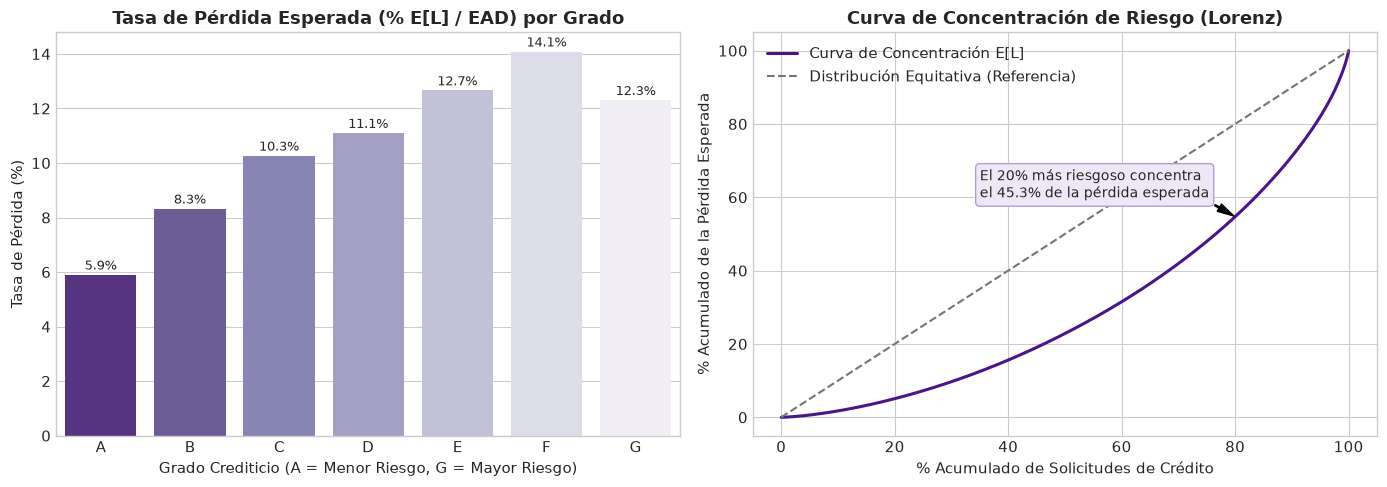

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Pérdida esperada por grado
if 'grade' in df_perdida.columns and df_perdida['grade'].notna().any():
    resumen_grado = df_perdida.groupby('grade').agg(
        creditos=('id', 'count'),
        ead_total=('ead_proxy', 'sum'),
        el_total=('perdida_esperada_proxy', 'sum'),
        pd_prom=('pd', 'mean'),
        lgd_prom=('lgd_proxy', 'mean')
    )
    resumen_grado['tasa_el_pct'] = (resumen_grado['el_total'] / resumen_grado['ead_total']) * 100
    
    sns.barplot(x=resumen_grado.index, y=resumen_grado['tasa_el_pct'], ax=axes[0], palette='Purples_r')
    axes[0].set_title('Tasa de Pérdida Esperada (% E[L] / EAD) por Grado', fontweight='bold')
    axes[0].set_ylabel('Tasa de Pérdida (%)')
    axes[0].set_xlabel('Grado Crediticio (A = Menor Riesgo, G = Mayor Riesgo)')
    for p in axes[0].patches:
        axes[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=9)

# 2. Curva de Concentración de Riesgo (Lorenz)
el_ordenado = np.sort(df_perdida['perdida_esperada_proxy'].to_numpy())
poblacion_acum = np.arange(1, len(el_ordenado) + 1) / len(el_ordenado) * 100
el_acum = np.cumsum(el_ordenado) / total_el * 100

axes[1].plot(poblacion_acum, el_acum, color='#4a148c', linewidth=2.2, label='Curva de Concentración E[L]')
axes[1].plot([0, 100], [0, 100], linestyle='--', color='#757575', label='Distribución Equitativa (Referencia)')
axes[1].set_title('Curva de Concentración de Riesgo (Lorenz)', fontweight='bold')
axes[1].set_xlabel('% Acumulado de Solicitudes de Crédito')
axes[1].set_ylabel('% Acumulado de la Pérdida Esperada')
axes[1].legend()

# Cuantificar regla 80/20
p80_idx = np.searchsorted(poblacion_acum, 80)
el_top20 = 100 - el_acum[p80_idx]
axes[1].annotate(f'El 20% más riesgoso concentra\nel {el_top20:.1f}% de la pérdida esperada',
                 xy=(80, el_acum[p80_idx]), xytext=(35, 60),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
                 fontsize=10, bbox=dict(boxstyle='round,pad=0.3', fc='#ede7f6', ec='#b39ddb'))

plt.tight_layout()
fig.savefig(RAIZ / 'reports/figura_perdida_esperada_analisis.png', dpi=200)
plt.show()

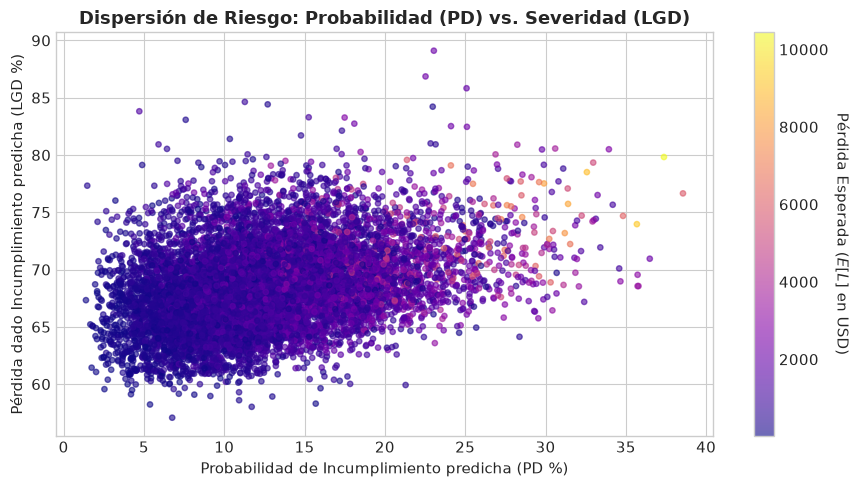

In [7]:
# Relación bivariada: PD vs. LGD coloreado por E[L]
plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    df_perdida['pd'] * 100,
    df_perdida['lgd_proxy'] * 100,
    c=df_perdida['perdida_esperada_proxy'],
    cmap='plasma',
    s=15,
    alpha=0.6
)
cbar = plt.colorbar(scatter)
cbar.set_label('Pérdida Esperada ($E[L]$ en USD)', rotation=270, labelpad=15)
plt.title('Dispersión de Riesgo: Probabilidad (PD) vs. Severidad (LGD)', fontweight='bold')
plt.xlabel('Probabilidad de Incumplimiento predicha (PD %)')
plt.ylabel('Pérdida dado Incumplimiento predicha (LGD %)')
plt.tight_layout()
plt.savefig(RAIZ / 'reports/figura_dispersion_pd_lgd_el.png', dpi=200)
plt.show()

--- 
### 6. Conclusiones y Aplicación Bancaria

1. **Diferenciación de Riesgo:** El producto $\mathbb{E}[L] = PD \cdot LGD \cdot EAD$ permite a la entidad financiera discriminar no solo quién tiene mayor propensión a fallar, sino cuál es el impacto financiero monetario real del impago. Solicitudes con alta PD pero montos reducidos pueden representar menor pérdida que préstamos cuantiosos con PD moderada.
2. **Provisiones NIIF 9 / CECL:** La estimación cuantitativa de $E[L]$ sirve como base objetiva para la constitución de reservas crediticias contra el margen de intermediación, garantizando que el banco mantenga solvencia frente a la pérdida esperada.
3. **Fijación de Tasas (*Risk-Based Pricing*):** La tasa de pérdida calculada ($E[L] / EAD$) establece el recargo mínimo técnico que debe cargarse a la tasa de interés de cada segmento para absorber el costo del riesgo sin destruir rentabilidad patrimonial.